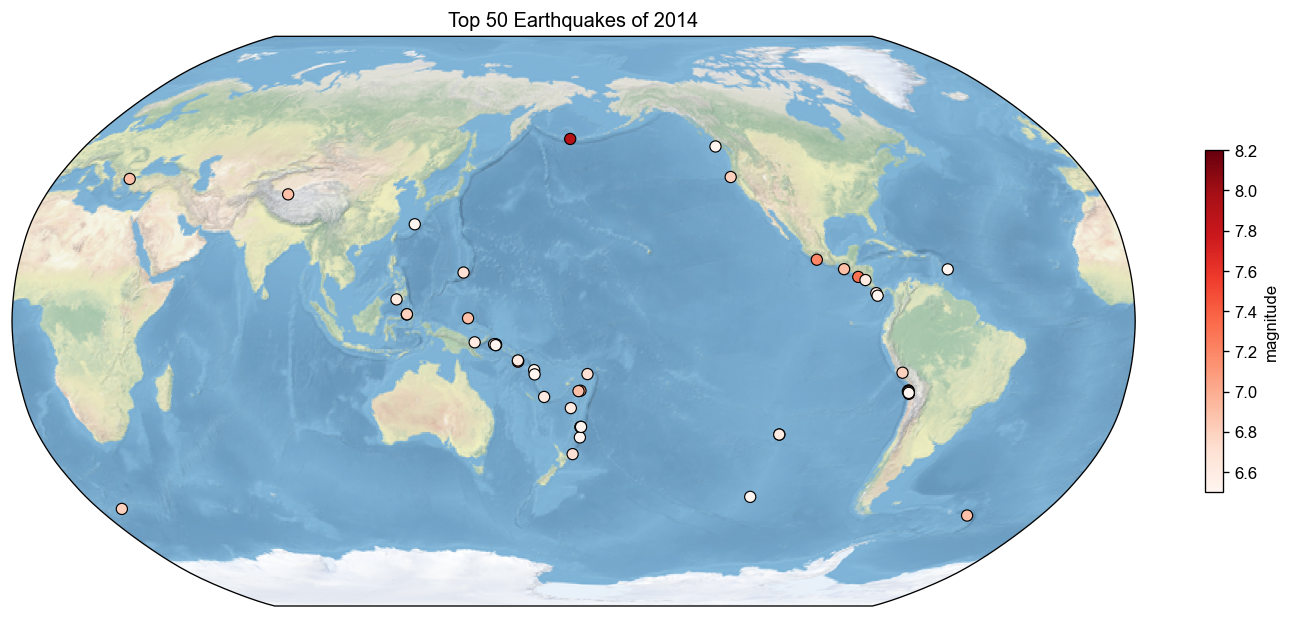

In [1]:
#第一题
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# 读取并筛选地震记录
file_path = r'D:\A_postgraduate\2026fall\Computer_and_Programming_for_env_research\assignments\homework4\usgs_earthquakes.csv'
earthquakes = pd.read_csv(file_path)
earthquakes = earthquakes[earthquakes['type'] == 'earthquake']
earthquakes = earthquakes.dropna(subset=['mag', 'longitude', 'latitude'])
top50 = earthquakes.sort_values(
    'mag', ascending=False, kind='stable'
).head(50)

# 设置投影并选择底图
plt.figure(figsize=(12, 6), dpi=120)
proj = ccrs.Robinson(central_longitude=180)
ax = plt.axes(projection=proj)
ax.stock_img()

# 红色渐变色代表震级
points = ax.scatter(
    top50['longitude'], top50['latitude'],
    c=top50['mag'], cmap='Reds', s=45,
    edgecolors='black', linewidths=0.7,
    transform=ccrs.PlateCarree(), zorder=3
)

plt.colorbar(points, ax=ax, shrink=0.5, pad=0.05, label='magnitude')
plt.title('Top 50 Earthquakes of 2014')
plt.tight_layout()
plt.show()

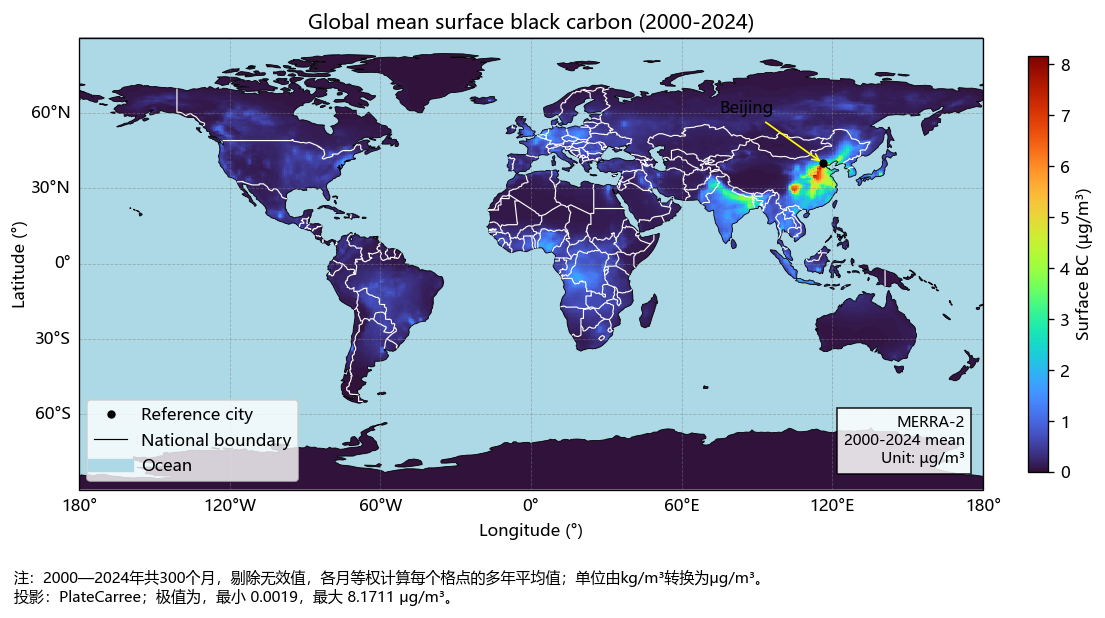

In [10]:
#第二题
#2.1
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 读取全球多年平均黑炭浓度，数据准备
ds = xr.open_dataset(r'D:\A_postgraduate\2026fall\Computer_and_Programming_for_env_research\assignments\homework4\MERRA2_BC_global_mean_2000_2024.nc', engine='netcdf4')
bc_map = ds['BCSMASS'] * 1e9
bc_map.attrs['units'] = 'µg m-3'

# 设置投影和色带
plt.figure(figsize=(12, 6), dpi=120)
proj = ccrs.PlateCarree()
ax = plt.axes(projection=proj)
bc_map.plot(
    ax=ax, transform=ccrs.PlateCarree(), cmap='turbo', vmin=0,
    cbar_kwargs={'label': 'Surface BC (µg/m³)', 'shrink': 0.75, 'pad': 0.04},
    zorder=0
)

# 海洋掩膜、国界线
ax.add_feature(cfeature.OCEAN, facecolor='lightblue', zorder=1)
ax.coastlines(resolution='110m', linewidth=0.5, zorder=2)
ax.add_feature(cfeature.BORDERS, edgecolor='white', linewidth=0.7, zorder=2)

# 经纬网、xy坐标轴
ax.set_xticks([])
ax.set_yticks([])
gl = ax.gridlines(
    crs=ccrs.PlateCarree(), draw_labels=True,
    linewidth=0.5, color='gray', alpha=0.5, linestyle='--'
)
gl.top_labels = False
gl.right_labels = False
gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))
ax.set_xlabel('Longitude (°)', labelpad=20)
ax.set_ylabel('Latitude (°)', labelpad=30)

# 参考点、文本框和图例
ax.plot(116.4, 39.9, 'ko', markersize=4,
        transform=ccrs.PlateCarree(), label='Reference city', zorder=3)
ax.annotate('Beijing', xy=(116.4, 39.9), xytext=(75, 60),
            transform=ccrs.PlateCarree(),
            arrowprops={'arrowstyle': '->', 'color': 'yellow'}, zorder=4)
ax.plot([], [], color='black', linewidth=0.7, label='National boundary')
ax.plot([], [], color='lightblue', linewidth=8, label='Ocean')
ax.legend(loc='lower left')
ax.text(0.98, 0.05, 'MERRA-2\n2000-2024 mean\nUnit: µg/m³',
        transform=ax.transAxes, ha='right', va='bottom', fontsize=9,
        bbox={'facecolor': 'white', 'edgecolor': 'black', 'alpha': 0.85})
ax.set_title('Global mean surface black carbon (2000-2024)')
# 注释
bc_min = float(bc_map.min())
bc_max = float(bc_map.max())
plt.gcf().text(
    0.08, 0.025,
    '注：2000—2024年共300个月，剔除无效值，各月等权计算每个格点的多年平均值；单位由kg/m³转换为μg/m³。\n'
    f'投影：PlateCarree；极值为，最小 {bc_min:.4f}，最大 {bc_max:.4f} μg/m³。',fontsize=9
)
plt.show()


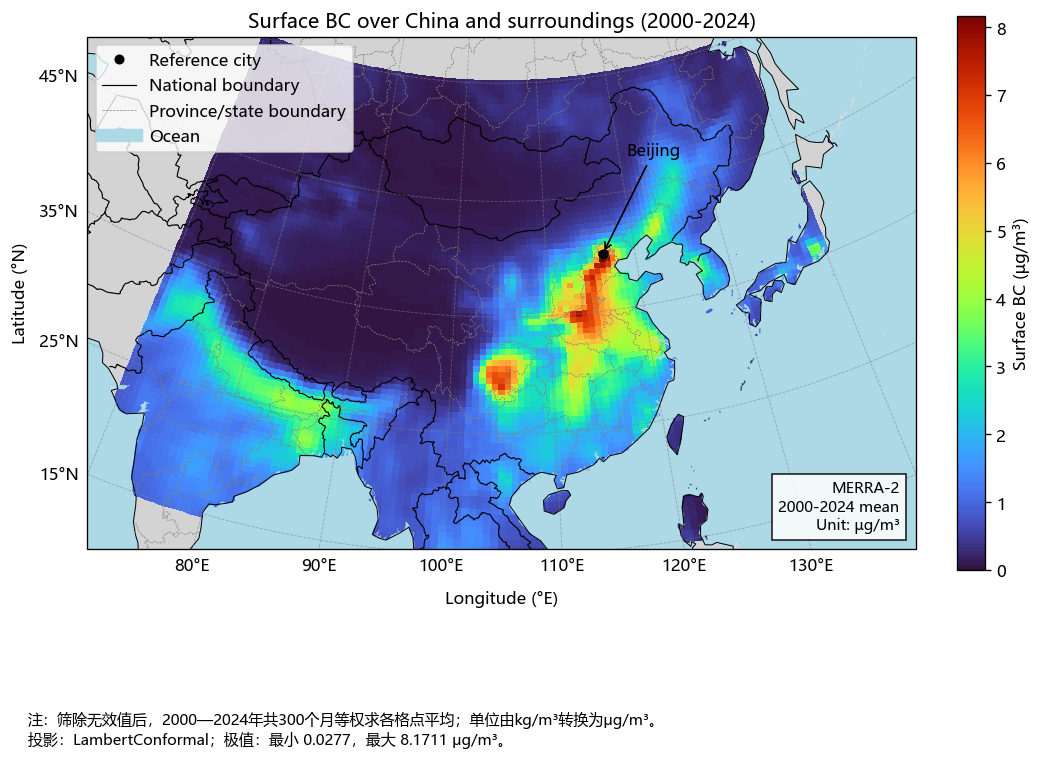

In [9]:
#2.2
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 读取中国及周边地区黑炭数据
ds = xr.open_dataset(r'D:\A_postgraduate\2026fall\Computer_and_Programming_for_env_research\assignments\homework3\MERRA2_BC_China_200001_202412.nc', engine='netcdf4')
bc = ds['BCSMASS']
valid_min, valid_max = bc.attrs['valid_range']
fill_value = bc.attrs['fmissing_value']
bc = bc.where((bc >= valid_min) & (bc <= valid_max) & (bc != fill_value))
bc_map = (bc * 1e9).mean(dim='time')
bc_map.attrs['units'] = 'µg m-3'

# 区域投影与色带设置
plt.figure(figsize=(11, 8), dpi=120)
proj = ccrs.LambertConformal(central_longitude=105, central_latitude=35)
ax = plt.axes(projection=proj)
ax.set_extent([70, 140, 15, 55], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=-1)
bc_map.plot(
    ax=ax, transform=ccrs.PlateCarree(), cmap='turbo', vmin=0,
    cbar_kwargs={'label': 'Surface BC (µg/m³)', 'shrink': 0.75, 'pad': 0.04},
    zorder=0
)

# 海洋掩膜、国界和省界
cartopy.config['pre_existing_data_dir'] = r'D:\A_postgraduate\2026fall\Computer_and_Programming_for_env_research\assignments\homework4\cartopy_data'
province_lines = cfeature.NaturalEarthFeature(
    'cultural', 'admin_1_states_provinces_lines', '50m', facecolor='none'
)
ax.add_feature(cfeature.OCEAN, facecolor='lightblue', zorder=1)
ax.coastlines(resolution='110m', linewidth=0.6, zorder=2)
ax.add_feature(cfeature.BORDERS, edgecolor='black', linewidth=0.7, zorder=2)
ax.add_feature(province_lines, edgecolor='grey', linewidth=0.4,
               linestyle='--', zorder=2)

# 经纬网与xy坐标轴
ax.set_xticks([])
ax.set_yticks([])
gl = ax.gridlines(
    crs=ccrs.PlateCarree(), draw_labels=True,
    x_inline=False, y_inline=False,
    linewidth=0.5, color='gray', alpha=0.6, linestyle='--'
)
gl.top_labels = False
gl.right_labels = False
gl.rotate_labels = False
gl.xlocator = mticker.FixedLocator(np.arange(70, 141, 10))
gl.ylocator = mticker.FixedLocator(np.arange(15, 56, 10))
ax.set_xlabel('Longitude (°E)', labelpad=25)
ax.set_ylabel('Latitude (°N)', labelpad=35)

# 参考点、注释和图例
ax.plot(116.4, 39.9, 'ko', markersize=5,
        transform=ccrs.PlateCarree(), label='Reference city', zorder=3)
ax.annotate('Beijing', xy=(116.4, 39.9), xytext=(121, 48),
            transform=ccrs.PlateCarree(),
            arrowprops={'arrowstyle': '->', 'color': 'black'}, zorder=4)
ax.plot([], [], color='black', linewidth=0.7, label='National boundary')
ax.plot([], [], color='grey', linewidth=0.4, linestyle='--',
        label='Province/state boundary')
ax.plot([], [], color='lightblue', linewidth=8, label='Ocean')
ax.legend(loc='upper left')
ax.text(0.98, 0.03, 'MERRA-2\n2000-2024 mean\nUnit: µg/m³',
        transform=ax.transAxes, ha='right', va='bottom', fontsize=9,
        bbox={'facecolor': 'white', 'edgecolor': 'black', 'alpha': 0.85}, zorder=5)
ax.set_title('Surface BC over China and surroundings (2000-2024)')
# 注释
bc_min = float(bc_map.min())
bc_max = float(bc_map.max())
plt.gcf().text(
    0.08, 0.025,
    '注：筛除无效值后，2000—2024年共300个月等权求各格点平均；单位由kg/m³转换为μg/m³。\n'
    f'投影：LambertConformal；极值：最小 {bc_min:.4f}，最大 {bc_max:.4f} μg/m³。', fontsize=9
)
plt.show()
